[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GNash19/paminaw/blob/v1.0.0/notebooks/03_score.ipynb)

# Paminaw! · Lab 3 · Score

A standalone copy of one lab from the PyCon Davao 2026 workshop *Speech Processing Using
PyTorch* (Nash Golosino and Aurora Manseras), for study after the event. WER, CER and the four scoring conventions of the paper.

Run **cell 0** first, then go from top to bottom with **Shift+Enter**. Scores are on the
**workshop subset (100 clips per language)**, not the paper's full-split numbers.

## 0 · Setup: run me first

This cell installs the workshop package `paminaw`, prints the versions of the libraries we
use, checks for a GPU and downloads the 200 audio clips. Wait for the **READY** line
(about a minute). If something fails, the message tells you how to fix it.

In [1]:
# Cell 0 · setup
import os
import subprocess
import sys

PAMINAW_REF = "v1.0.0"  # the workshop release on GitHub
SMOKE_TEST = os.environ.get("PAMINAW_SMOKE") == "1"  # quick test mode: 2 clips, whisper-tiny

if "google.colab" in sys.modules:
    print(f"Installing paminaw {PAMINAW_REF} ...")
    url = f"paminaw @ git+https://github.com/GNash19/paminaw@{PAMINAW_REF}"
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", url],
                       capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stderr[-1500:])
        raise SystemExit("Error: Could not install paminaw. Fix: check that Colab says "
                         "'Connected' (top right), then run this cell again.")
try:
    import paminaw
except ModuleNotFoundError:
    raise SystemExit("Error: paminaw is not installed. Fix: outside Colab, run "
                     "`pip install -e .` in the repo folder (see docs/OFFLINE.md).") from None

SETUP = paminaw.setup_workshop(smoke=SMOKE_TEST)

Versions: python 3.13.7 · torch 2.11.0+cpu · torchaudio 2.11.0+cpu · transformers 5.18.0 · datasets 4.8.5 · jiwer 4.0.0
No GPU: running on CPU. Everything works; Lab 2b will load precomputed MMS outputs. (Optional: Runtime → Change runtime type → T4 GPU.)
READY: 200 clips (100 Tagalog + 100 Cebuano, workshop subset) · cpu (float32) · 0 s


## 3 · Score (about 20 minutes)

**WER** (word error rate) counts the **s**ubstitutions, **d**eletions and **i**nsertions
needed to turn the model's words into the reference words, divided by the number of
reference words: WER = (S + D + I) / N. It can go above 100% when a model adds many extra
words. **CER** does the same with characters.

Before comparing, texts are usually **normalised**: lowercased, punctuation removed, and
so on. *How* you normalise is a choice. The paper behind this workshop (Golosino, Morales
& Adlaon 2026) shows that this choice alone moves Whisper's Tagalog WER by 15 points and
can change which model ranks first.

In [2]:
import os

try:
    import paminaw
except ModuleNotFoundError:
    raise SystemExit("Error: Run cell 0 (Setup) at the top of the notebook first.") from None

# Lab 3 setup: safe to run even if you skipped Labs 1 and 2
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from paminaw.compare import (PAPER_TABLE3_WER, convention_table, ranking_table,
                             score_systems, top_substitutions)
from paminaw.plotting import plot_convention_bars, set_style

SMOKE_TEST = os.environ.get("PAMINAW_SMOKE") == "1"
paminaw.set_seed()
set_style()
pd.set_option("display.max_colwidth", 90)
refs = paminaw.load_manifest()  # the 200 references (FLEURS "transcription" field)

MINE = Path("outputs/whisper_small_yours.csv")
if MINE.exists():
    mine = pd.read_csv(MINE, keep_default_na=False)
    source = "your Lab 2 run"
else:  # skipped Lab 2: use a ready-made Whisper-small run on the same clips
    n = 2 if SMOKE_TEST else 20
    mine = pd.read_csv(paminaw.data.data_file("precomputed/whisper-small.csv"),
                       keep_default_na=False).rename(columns={"hypothesis_raw": "hypothesis"})
    mine = mine.groupby("lang").head(n)
    source = "a ready-made Whisper-small run (you skipped Lab 2)"
n_mine = mine.groupby("lang").size().min()
print(f"Whisper-small outputs: {len(mine)} clips from {source}.")

Whisper-small outputs: 40 clips from your Lab 2 run.


### Exercise 5 · Write `normalize()` yourself

The paper's **primary** convention has four steps:
1. Unicode **NFC** (so `ñ` is always one character, never `n` + a separate tilde)
2. **case-fold** (lowercase, done properly for every language)
3. replace every character that is not a letter, digit, `_` or space **with a space**
4. **collapse** runs of spaces into one, and trim the ends

Steps 1 and 2 are done. Finish steps 3 and 4 (hint: `re.sub`), then run the check below.

In [3]:
import re
import unicodedata


def normalize(text):
    text = unicodedata.normalize("NFC", text)  # 1. compose characters
    text = text.casefold()  # 2. lowercase
    # 3. TODO: text = re.sub(r"[^\w\s]", " ", text)
    # 4. TODO: text = re.sub(r"\s+", " ", text).strip()
    return text

In [4]:
examples = ["Maayong buntag, Doc!", "Kumusta  ka na?", "Sen\u0303or N\u0303ino",
            "ang populasyon kay 800. kini", "bag-ohon"]
for ex in examples:
    ok = normalize(ex) == paminaw.normalize(ex, "primary")
    hint = "" if ok else f"   (expected {paminaw.normalize(ex)!r})"
    print("PASS" if ok else "FAIL", f"{ex!r:34} → {normalize(ex)!r}{hint}")
print("\nFrom here on we use paminaw.normalize, which also has the other three conventions.")

FAIL 'Maayong buntag, Doc!'             → 'maayong buntag, doc!'   (expected 'maayong buntag doc')
FAIL 'Kumusta  ka na?'                  → 'kumusta  ka na?'   (expected 'kumusta ka na')
PASS 'Señor Ñino'                     → 'señor ñino'
FAIL 'ang populasyon kay 800. kini'     → 'ang populasyon kay 800. kini'   (expected 'ang populasyon kay 800 kini')
FAIL 'bag-ohon'                         → 'bag-ohon'   (expected 'bag ohon')

From here on we use paminaw.normalize, which also has the other three conventions.


### Two worked examples

**1 · `kumusta ka na` → `kumusta kana`.** The model merged two words. That is one
substitution (*ka* → *kana*) plus one deletion (*na*) over 3 reference words:
WER = **2/3**. What about CER? It depends on a definition most people never look at:

* `jiwer.cer`, the library default, **counts spaces as characters**: 13 reference
  characters and one missing space, so CER = **1/13 ≈ 7.7%**.
* The paper computes CER over **non-whitespace characters only**: `kumustakana` against
  `kumustakana` is 0 errors out of 11, so CER = **0/11 = 0%**.

Same strings, two "correct" CERs. Just like normalisation, the definition has to be
stated next to the number.

**2 · `Maayong buntag, Doc!` → `maayong buntag doc`.** Every word differs if you compare
exactly as written, so WER = **100%** under `none`. After the primary normalisation the
texts are identical, so WER = **0%**.

In [5]:
ref, hyp = "kumusta ka na", "kumusta kana"
print(f"WER                          : {paminaw.wer(ref, hyp):.4f}  (2/3 = {2 / 3:.4f})")
print(f"CER, jiwer default (spaces)  : {paminaw.cer_jiwer_default(ref, hyp):.4f}  (1/13 = {1 / 13:.4f})")
print(f"CER, paper (no whitespace)   : {paminaw.cer(ref, hyp):.4f}  (0/11)")

ref, hyp = "Maayong buntag, Doc!", "maayong buntag doc"
pd.DataFrame(
    [{"convention": c, "reference": paminaw.normalize(ref, c), "hypothesis": paminaw.normalize(hyp, c),
      "WER %": 100 * paminaw.wer(paminaw.normalize(ref, c), paminaw.normalize(hyp, c))}
     for c in paminaw.CONVENTIONS]
).round(1)

WER                          : 0.6667  (2/3 = 0.6667)
CER, jiwer default (spaces)  : 0.0769  (1/13 = 0.0769)
CER, paper (no whitespace)   : 0.0000  (0/11)


,convention,reference,hypothesis,WER %
0,none,"Maayong buntag, Doc!",maayong buntag doc,100.0
1,casefold,"maayong buntag, doc!",maayong buntag doc,66.7
2,primary,maayong buntag doc,maayong buntag doc,0.0
3,strict,maayong buntag doc,maayong buntag doc,0.0


### Your Whisper-small: raw vs normalised

The FLEURS references are lowercase with almost no punctuation. Whisper writes capitals
and punctuation. Watch what that does to the score.

In [6]:
mine_sys = mine.assign(system="Whisper-small (yours)")[["system", "lang", "idx", "hypothesis"]]
label = f"workshop subset ({n_mine} clips per language)"
s_mine = score_systems(refs, mine_sys, conventions=["none", "primary"], subset_label=label)
print(f"Scores on the {label}; not the paper's full-split numbers.")
s_mine.pivot_table(index="lang", columns="convention", values=["wer", "cer"]).round(1)

Scores on the workshop subset (20 clips per language); not the paper's full-split numbers.


cer           wer        
convention  none primary  none primary
lang                                  
cebuano     14.2     9.6  61.0    49.1
tagalog     13.3     9.5  35.7    24.5

### The paper's three systems, four conventions

These are the paper's own, unnormalised outputs from Whisper large-v3, MMS-1B-all and
SeamlessM4T v2 Large for the **same 200 clips**. Nothing is re-run: only the scoring
changes.

In [7]:
pre = paminaw.load_precomputed()
scores = score_systems(refs, pre, subset_label="workshop subset (100 clips)")
print("WER (%) on the workshop subset (100 clips per language):")
convention_table(scores, "wer")

WER (%) on the workshop subset (100 clips per language):


convention                     none  casefold  primary  strict  sensitivity
system               lang                                                  
MMS-1B-all           cebuano  14.89     14.89    13.89   13.60         1.30
                     tagalog  14.10     14.10    13.51   12.69         1.41
SeamlessM4T v2 Large cebuano  41.91     37.88    37.72   38.00         4.18
                     tagalog  25.42     21.94    21.35   21.52         4.07
Whisper large-v3     cebuano  54.07     47.04    40.60   40.65        13.47
                     tagalog  26.12     19.01    11.90   11.86        14.26

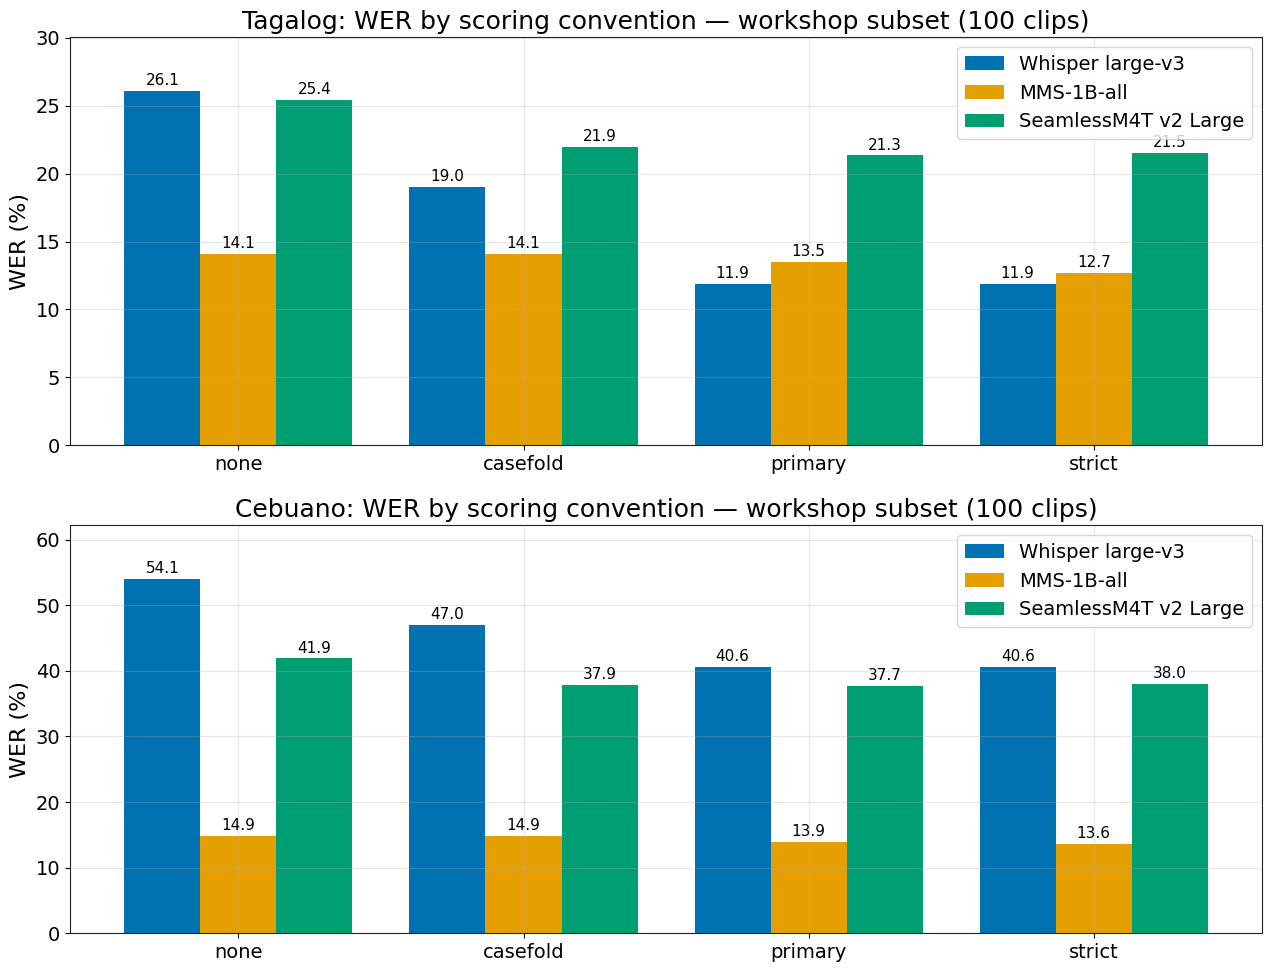

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(13, 10))
for ax, lang in zip(axes, ["tagalog", "cebuano"]):
    plot_convention_bars(scores, lang, ax=ax)
plt.tight_layout()
plt.show()

In [9]:
paper = pd.DataFrame(PAPER_TABLE3_WER).T
paper.index.names = ["system", "lang"]
print("For comparison, the paper's Table 3: WER (%) on the FULL test splits "
      "(964 Tagalog, 541 Cebuano utterances):")
paper

For comparison, the paper's Table 3: WER (%) on the FULL test splits (964 Tagalog, 541 Cebuano utterances):


none  casefold  primary  strict
system               lang                                     
Whisper large-v3     tagalog  27.11     19.12    12.23   12.14
                     cebuano  56.69     49.56    43.32   43.47
MMS-1B-all           tagalog  13.00     13.00    12.50   11.87
                     cebuano  14.47     14.47    13.62   13.46
SeamlessM4T v2 Large tagalog  25.26     21.09    20.51   20.41
                     cebuano  41.68     37.59    37.44   37.76

### Exercise 6 · Does the ranking change?

Rank 1 = lowest WER. Look along each language. **Question:** Under which convention would you pick a
different "best" model for Tagalog? Is any result on Cebuano robust to every convention?

In [10]:
ranking_table(scores, "wer")

system              MMS-1B-all  SeamlessM4T v2 Large  Whisper large-v3
lang    convention                                                    
cebuano none                 1                     2                 3
        casefold             1                     2                 3
        primary              1                     2                 3
        strict               1                     2                 3
tagalog none                 1                     2                 3
        casefold             1                     3                 2
        primary              2                     3                 1
        strict               2                     3                 1

## Wrap-up: where the models fall short

* **Language coverage beats size.** Whisper large-v3 (1.55 B parameters) has no Cebuano
  token and degrades from 12 % to 43 % WER going from Tagalog to Cebuano. MMS (1 B
  parameters) declares Cebuano and barely moves (12.5 % → 13.6 %).
* **It writes the nearest language it knows.** Below are Whisper large-v3's most frequent
  Cebuano → Tagalog substitutions on our subset.
* **Read speech is the easy case.** FLEURS sentences are read aloud from prepared text, so
  these numbers are an upper bound. Spontaneous, code-switched Cebuano–Tagalog–English
  speech is much harder, and there is not yet a public benchmark for it.
* **Scoring is part of the result.** Always report the normalisation convention and
  which CER definition you used.

**What fine-tuning involves.** Collect transcribed audio in the target language (hours,
not thousands of hours), then train only a small part of the model. For MMS that is a new
**adapter** of about 2 M parameters, while the billion shared weights stay frozen. Hugging
Face has a step-by-step guide: [Fine-tuning MMS adapter models](https://huggingface.co/blog/mms_adapters).

**Links**
* Paper data, hypotheses and scoring code: [Zenodo 10.5281/zenodo.23010849](https://doi.org/10.5281/zenodo.23010849)
* Workshop repository: <https://github.com/GNash19/paminaw> (questions → Issues)

*Salamat kaayo! Maraming salamat!*

In [11]:
import os

try:
    import paminaw
except ModuleNotFoundError:
    raise SystemExit("Error: Run cell 0 (Setup) at the top of the notebook first.") from None

import pandas as pd
from paminaw.compare import top_substitutions

large = paminaw.load_precomputed("Whisper large-v3")
ceb_refs = paminaw.load_manifest("cebuano")
both = ceb_refs.merge(large[large.lang == "cebuano"], on=["lang", "idx"])
print("Whisper large-v3 on 100 Cebuano clips: most frequent word substitutions "
      "(reference → output)")
top_substitutions(both["transcription"], both["hypothesis"], n=10)

Whisper large-v3 on 100 Cebuano clips: most frequent word substitutions (reference → output)


,reference,hypothesis,count
0,nga,na,58
1,nga,ng,38
2,ug,at,24
3,ug,o,22
4,og,o,18
5,og,at,13
6,kon,kung,10
7,usab,usap,9
8,niini,ini,5
9,usa,sa,4
